# Random Forest

Random Forest is a supervised machine learning algorithm that belongs to the ensemble learning family. It can be used for both classification and regression tasks.

The algorithm works by constructing multiple Decision Trees during training and combining their predictions to produce a final result. Each tree is trained using a different bootstrap sample of the dataset and considers random subsets of features when making decisions.

For classification tasks, Random Forest uses majority voting to determine the final predicted class. For regression tasks, it typically calculates the average of predictions from all the trees.

By combining multiple trees, Random Forest aims to improve prediction accuracy, reduce overfitting, and produce more stable results than relying on a single Decision Tree.

## How Random Forest Works

1. **Bootstrap sampling:** Random samples are drawn from the original training dataset with replacement.
2. **Random feature selection:** Each tree considers a random subset of available features when determining splits.
3. **Tree construction:** Multiple Decision Trees are independently trained using the sampled data.
4. **Prediction aggregation:** Predictions from all trees are combined through majority voting for classification or averaging for regression.

## Key Concepts

- **Ensemble learning:** Combining multiple models to improve predictive performance.
- **Bootstrap sampling:** Creating different training samples through sampling with replacement.
- **Feature randomness:** Selecting subsets of features when building decision trees.
- **Majority voting:** Choosing the most frequently predicted class in classification.
- **Averaging:** Combining numerical predictions in regression.
- **Out-of-bag evaluation:** Estimating model performance using observations not selected in individual bootstrap samples.

## Advantages

- Supports both classification and regression.
- Often generalizes better than a single Decision Tree.
- Captures nonlinear relationships.
- Handles datasets with many features.
- Does not require feature scaling.
- Provides feature importance estimates.

## Limitations

- More computationally expensive than a single Decision Tree.
- Requires more memory when building many trees.
- Less interpretable than an individual Decision Tree.
- Can become slower as the number and depth of trees increase.



In [65]:
# imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import mean_squared_error,mean_absolute_error, r2_score
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_auc_score)

# Regression
## Position  Salary dataset

In [8]:
salary_df = pd.read_csv('../Datasets/Position_Salaries.csv')
salary_df

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [11]:
salary_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Position  10 non-null     object
 1   Level     10 non-null     int64 
 2   Salary    10 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 372.0+ bytes


In [12]:
salary_df.describe()

,Level,Salary
count,10.00000,10.000000
mean,5.50000,249500.000000
std,3.02765,299373.883668
min,1.00000,45000.000000
25%,3.25000,65000.000000
50%,5.50000,130000.000000
75%,7.75000,275000.000000
max,10.00000,1000000.000000


In [13]:
# features and target
X = salary_df.iloc[:,1:2].values
y = salary_df.iloc[:,2].values

In [17]:
# Encoding
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()

for col in salary_df.select_dtypes(include=['object']).columns:
    salary_df[col] = label_encoder.fit_transform(salary_df[col])

In [18]:
# split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

In [19]:
# model
regressor = RandomForestRegressor(n_estimators=100,random_state=42,oob_score=True)

regressor.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


In [22]:
# predictions and evaluation
print("Out-of-Bag Score:", regressor.oob_score_)

y_pred = regressor.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

r2 = r2_score(y_test, y_pred)
print("R-squared:", r2)

Out-of-Bag Score: 0.2280694384742593
Mean Squared Error: 616145000.0
R-squared: 0.9878292345679013


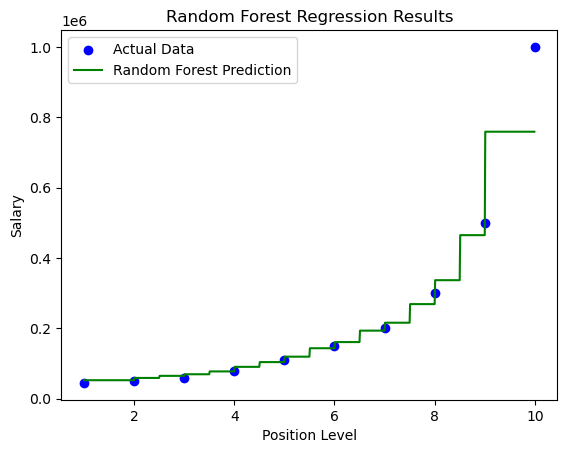

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

X_grid = np.arange(min(X), max(X), 0.01).reshape(-1,1)

plt.scatter(X, y, color='blue', label="Actual Data")
plt.plot(X_grid, regressor.predict(X_grid), color='green', label="Random Forest Prediction")

plt.title("Random Forest Regression Results")
plt.xlabel('Position Level')
plt.ylabel('Salary')
plt.legend()
plt.show()

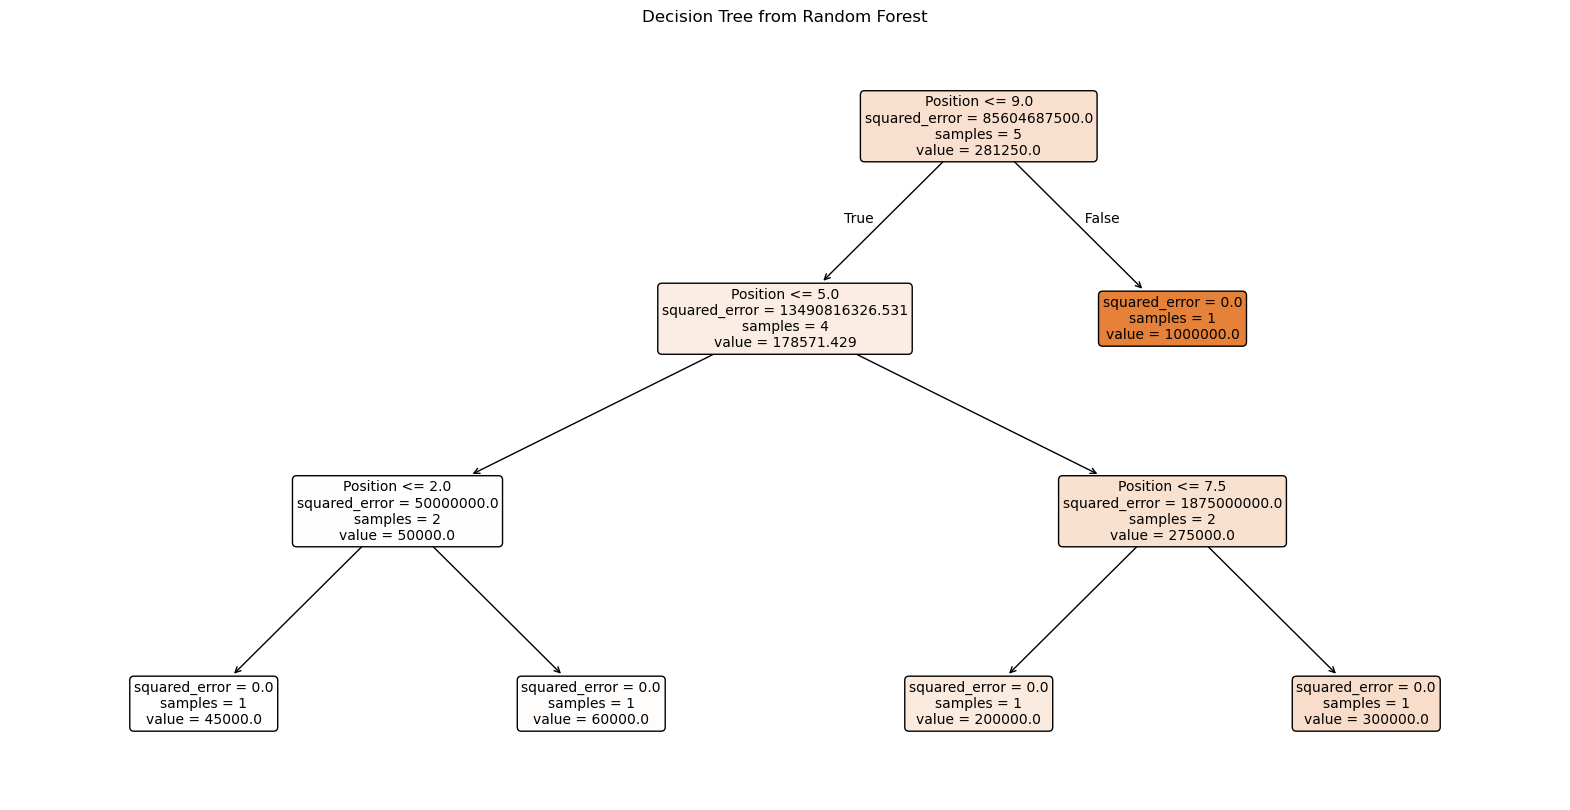

In [27]:
# single decision tree
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

tree_to_plot = regressor.estimators_[0]

plt.figure(figsize=(20, 10))
plot_tree(tree_to_plot, feature_names=salary_df.columns.tolist(), filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree from Random Forest")
plt.show()

## California Housing Dataset

In [31]:
# load dataset
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing()

housing_df = pd.DataFrame(housing.data,columns=housing.feature_names)

housing_df['target'] = housing.target

print(housing_df.shape)
housing_df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [32]:
housing_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   target      20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [33]:
housing_df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [37]:
# missing values
housing_df.isnull().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
target        0
dtype: int64

In [34]:
# target distribution analysis
housing_df['target'].describe()

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: target, dtype: float64

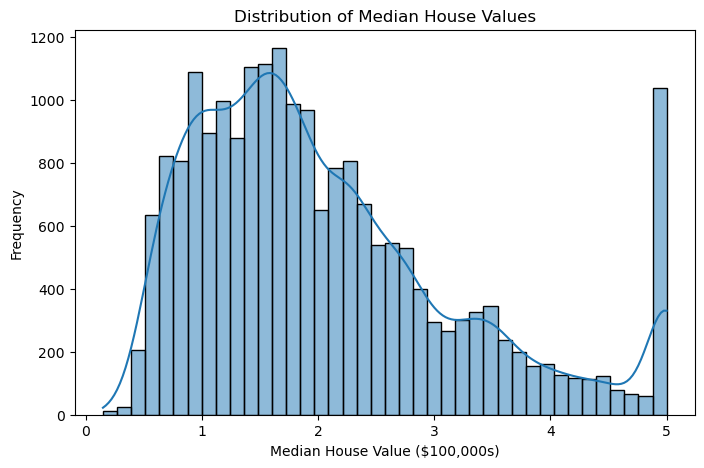

In [35]:
plt.figure(figsize=(8, 5))
sns.histplot(housing_df['target'], bins=40, kde=True)

plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value ($100,000s)')
plt.ylabel('Frequency')
plt.show()

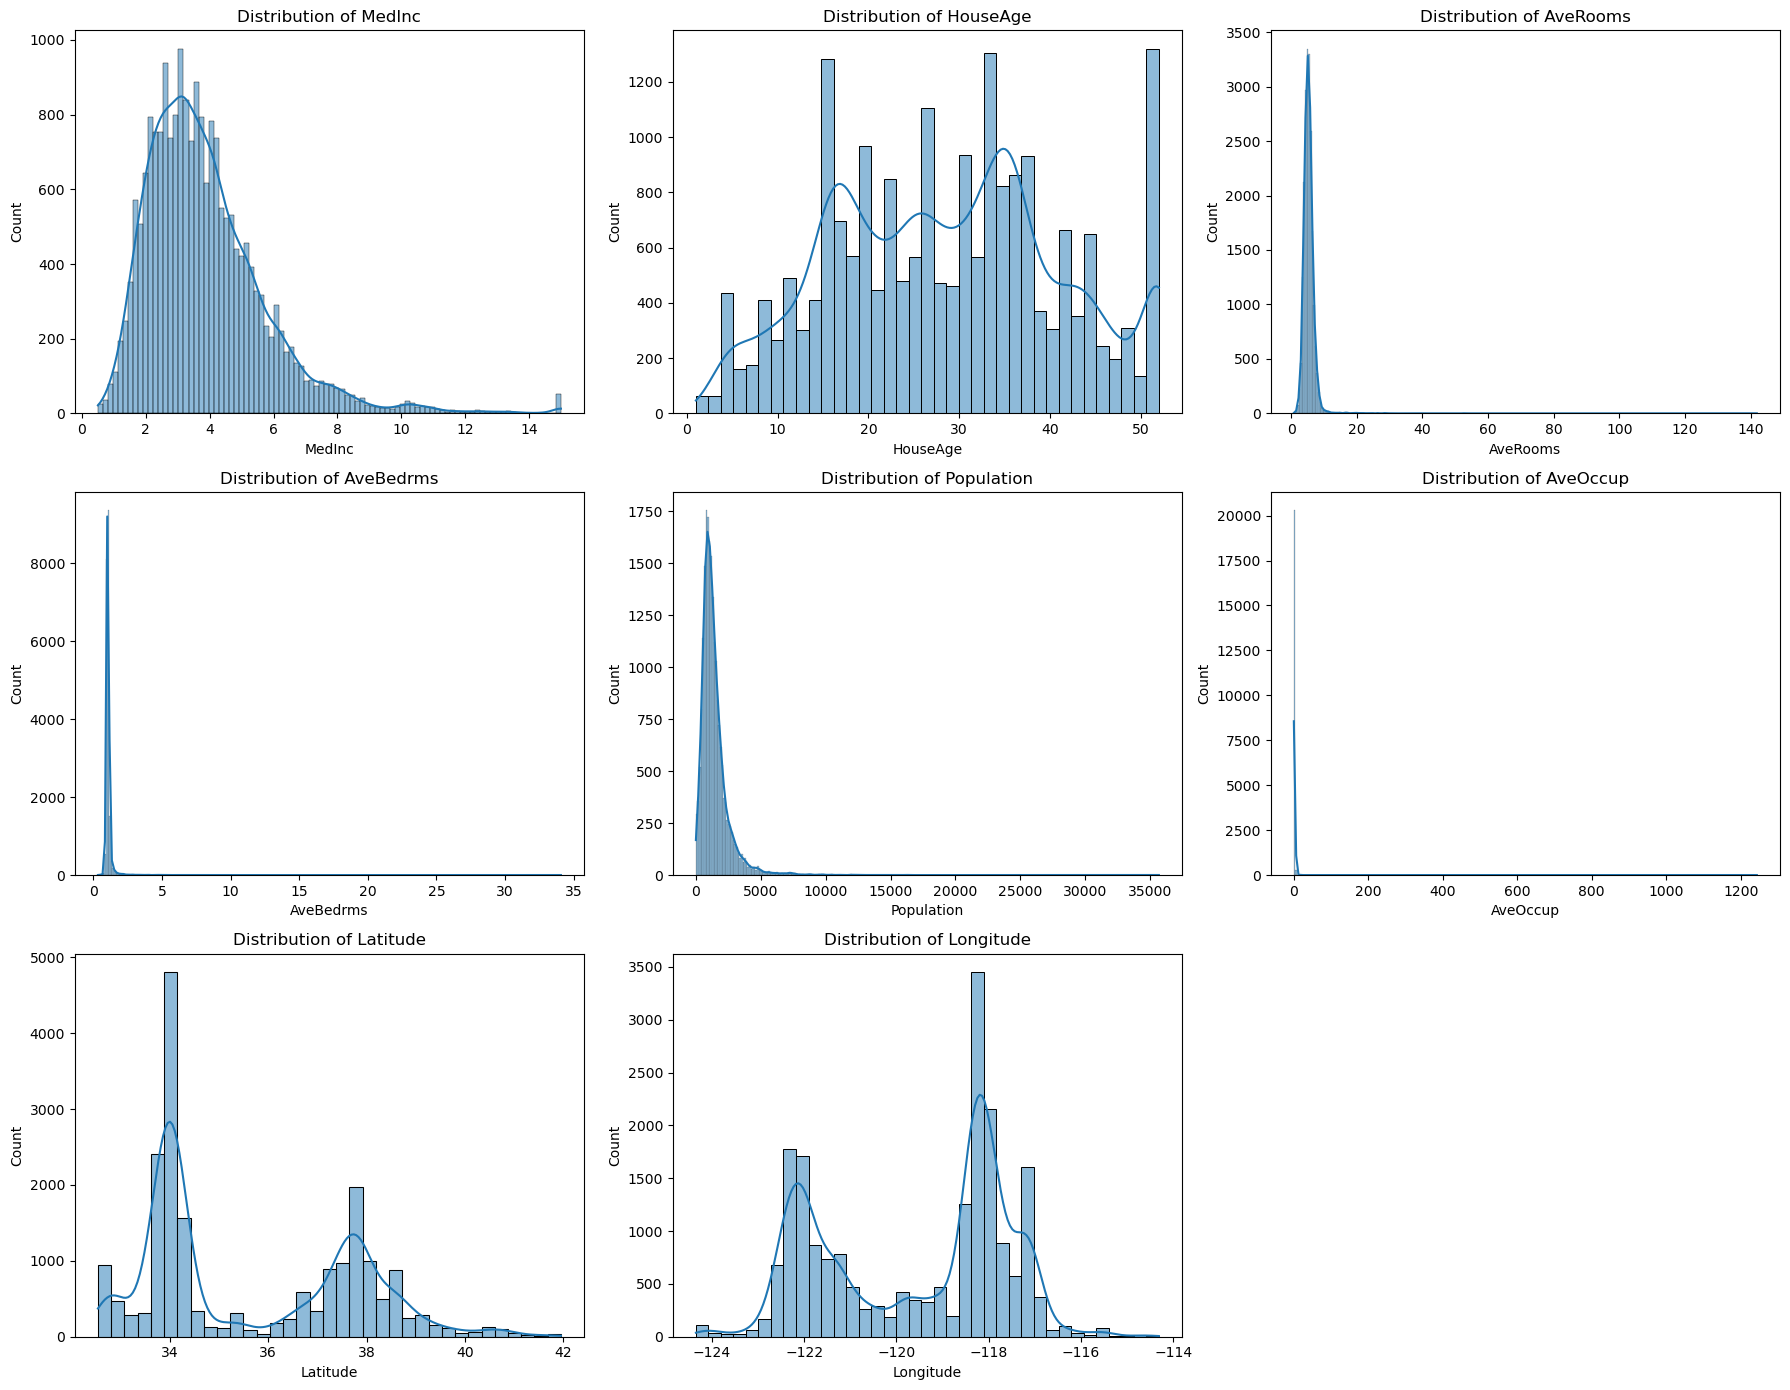

In [38]:
# Feature distributions
features = housing_df.drop(columns='target').columns

n_cols = 3
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 14))
axes = axes.flatten()

for i, column in enumerate(features):
    sns.histplot(data=housing_df, x=column, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {column}')

for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

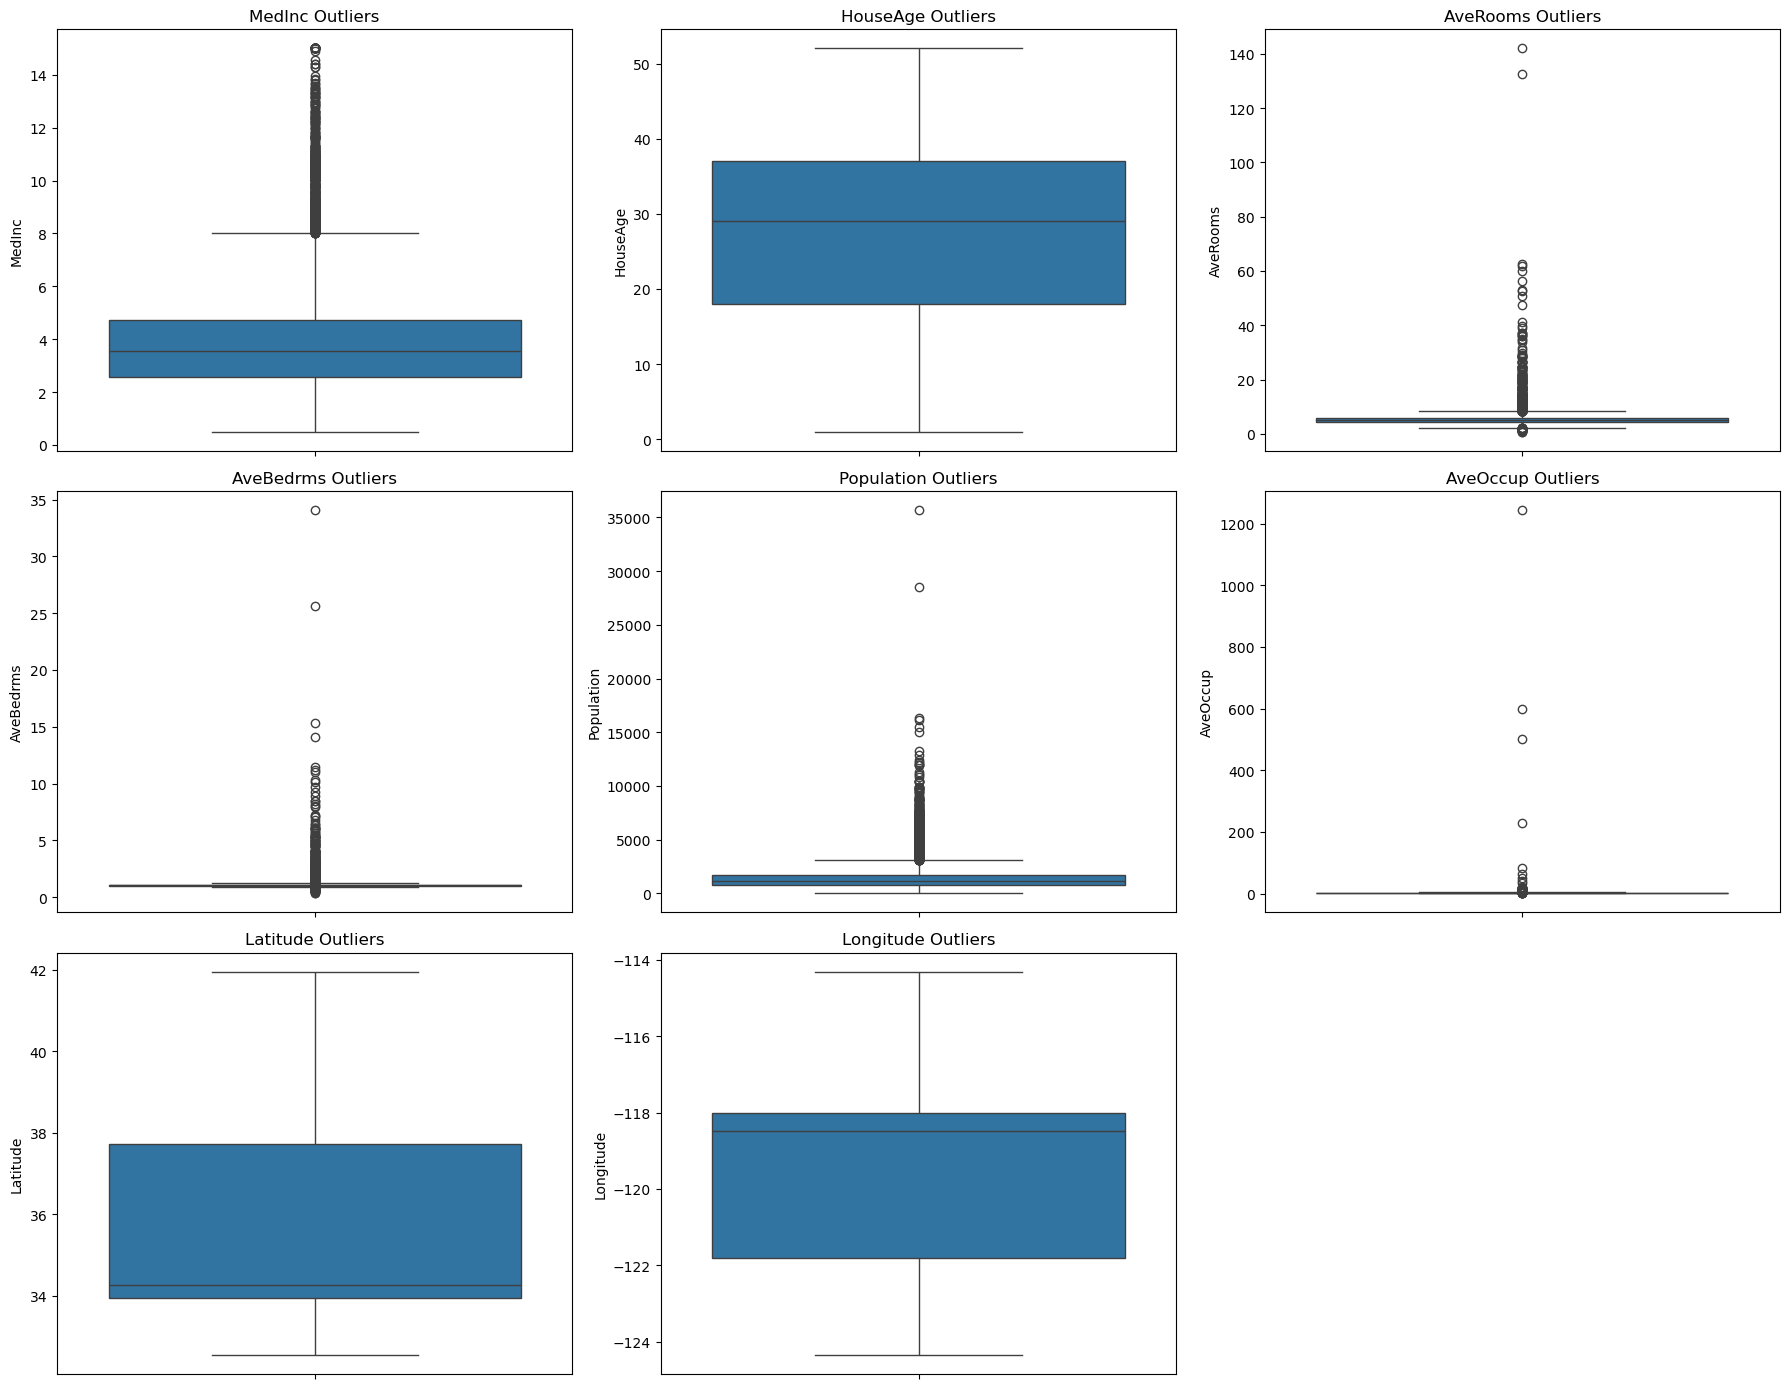

In [39]:
# outlier analysis
features = housing_df.drop(columns='target').columns

n_cols = 3
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 14))
axes = axes.flatten()

for i, column in enumerate(features):
    sns.boxplot(data=housing_df, y=column, ax=axes[i])
    axes[i].set_title(f'{column} Outliers')

for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

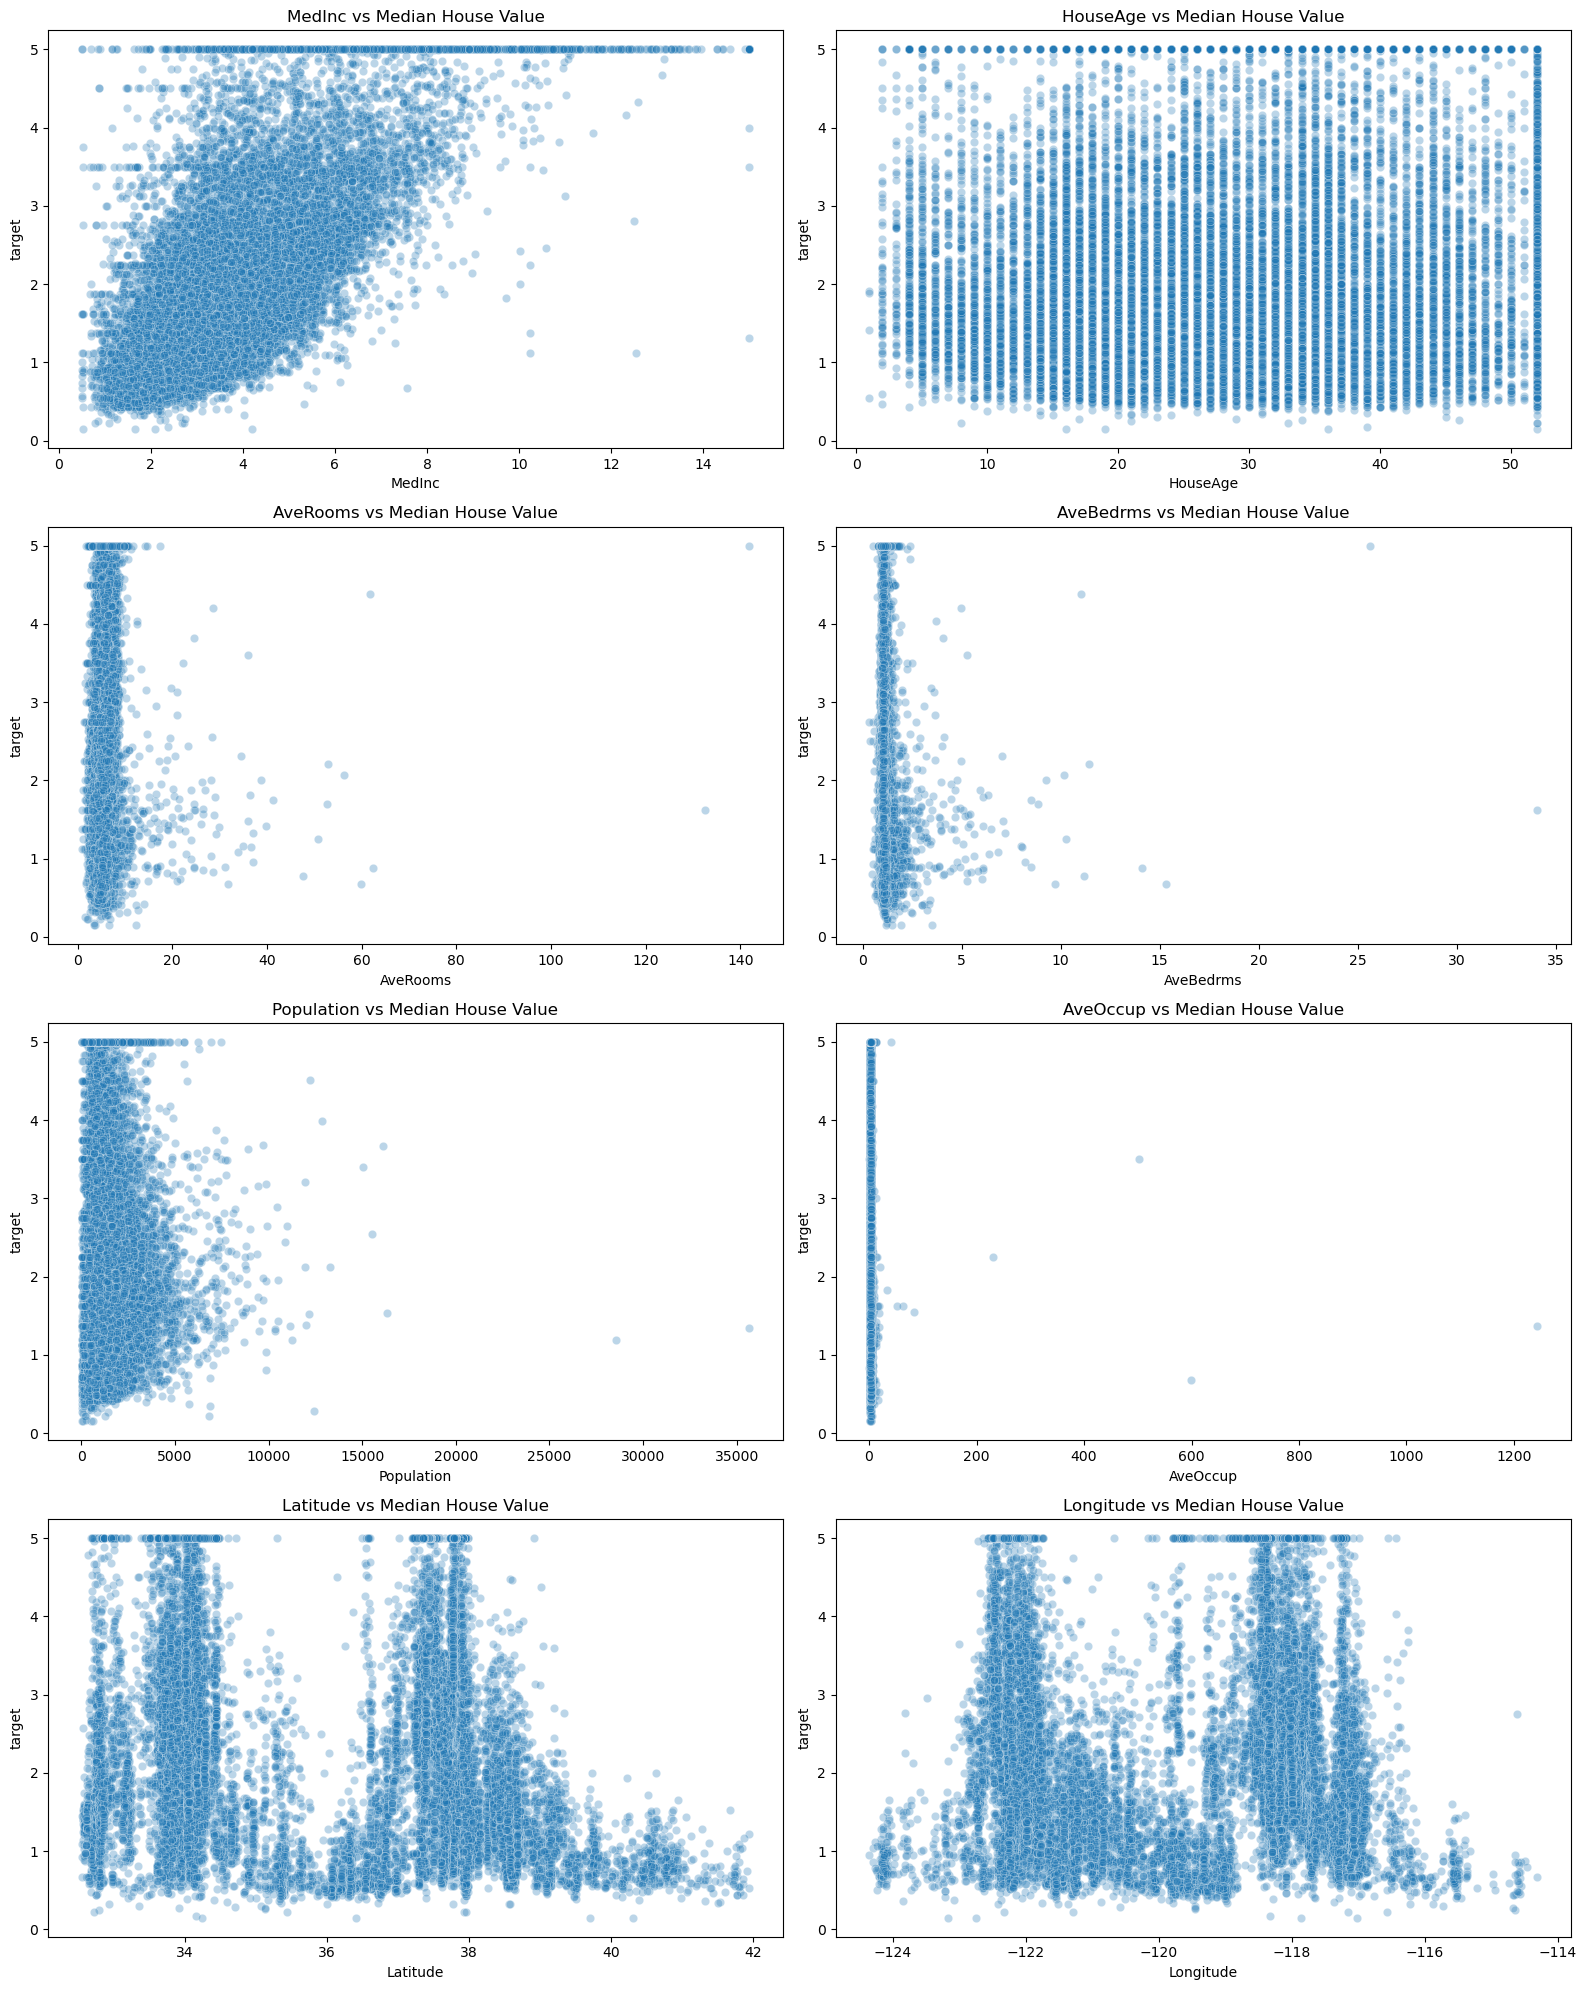

In [40]:
# Feature rlships with target
selected_features = [
    'MedInc',
    'HouseAge',
    'AveRooms',
    'AveBedrms',
    'Population',
    'AveOccup',
    'Latitude',
    'Longitude'
]

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, column in enumerate(selected_features):
    sns.scatterplot(data=housing_df,x=column,y='target',alpha=0.3,ax=axes[i])
    axes[i].set_title(f'{column} vs Median House Value')

plt.tight_layout()
plt.show()

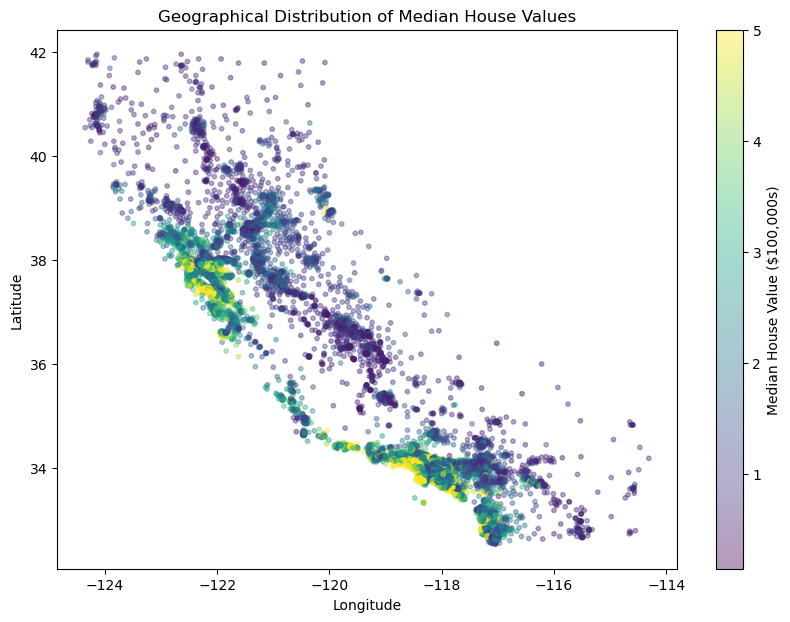

In [41]:
# Geographic distribution of house values
plt.figure(figsize=(10, 7))

scatter = plt.scatter(housing_df['Longitude'],housing_df['Latitude'],c=housing_df['target'],cmap='viridis', alpha=0.4,s=10)

plt.colorbar(scatter, label='Median House Value ($100,000s)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Geographical Distribution of Median House Values')
plt.show()

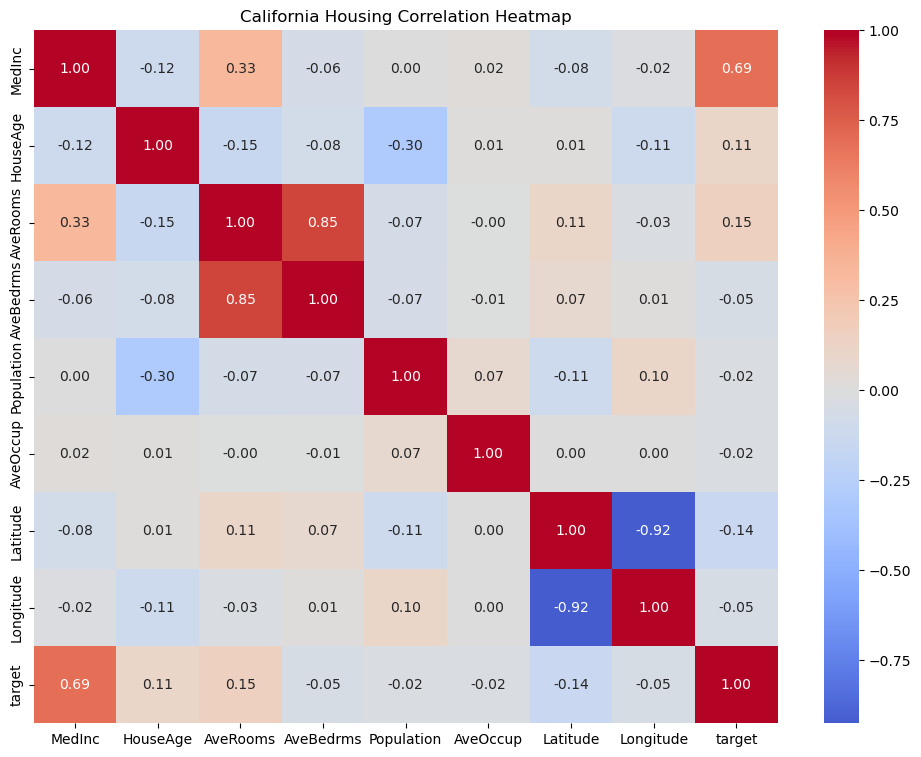

In [42]:
# Correlation analysis
plt.figure(figsize=(12, 9))

sns.heatmap(housing_df.corr(),annot=True,cmap='coolwarm',center=0,fmt='.2f')

plt.title('California Housing Correlation Heatmap')
plt.show()

In [43]:
# separate features and targets
X = housing_df.drop(columns='target')
y = housing_df['target']
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 8)
Target shape: (20640,)


In [44]:
# split dataset
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


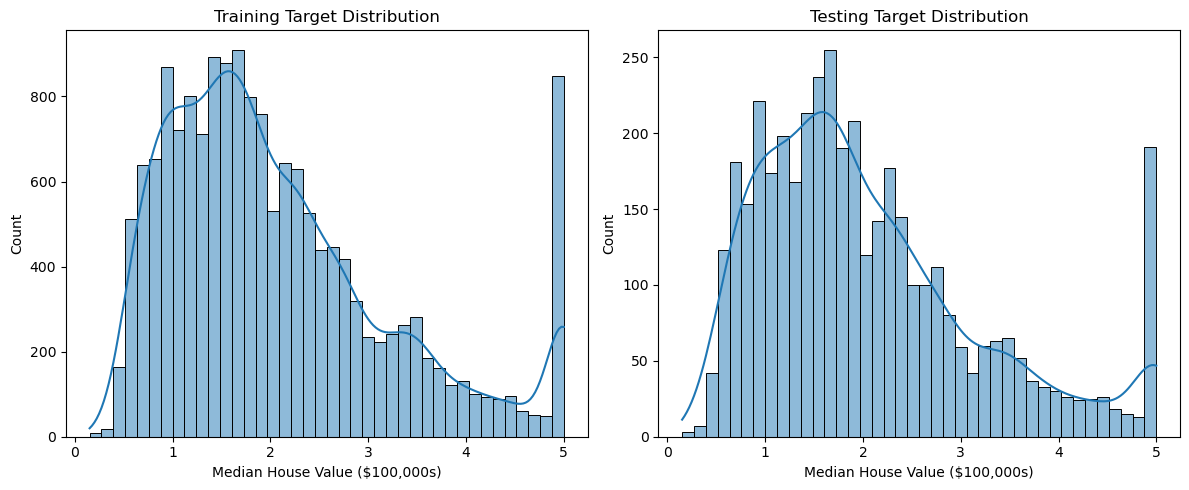

In [46]:
# target disribution after split
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(y_train, bins=40, kde=True, ax=axes[0])
axes[0].set_title('Training Target Distribution')
axes[0].set_xlabel('Median House Value ($100,000s)')

sns.histplot(y_test, bins=40, kde=True, ax=axes[1])
axes[1].set_title('Testing Target Distribution')
axes[1].set_xlabel('Median House Value ($100,000s)')

plt.tight_layout()
plt.show()

In [47]:
# Modelling
rf_regressor = RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1)

rf_regressor.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [48]:
# predictions
y_train_pred = rf_regressor.predict(X_train)
y_test_pred = rf_regressor.predict(X_test)

In [51]:
# Model evaluation
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

MAE:  0.3275
MSE:  0.2554
RMSE: 0.5053
R² Score: 0.8051


#### The model demonstrates good predictive performance, although there is still room for improvement. The RMSE being higher than MAE suggests some larger prediction errors. 

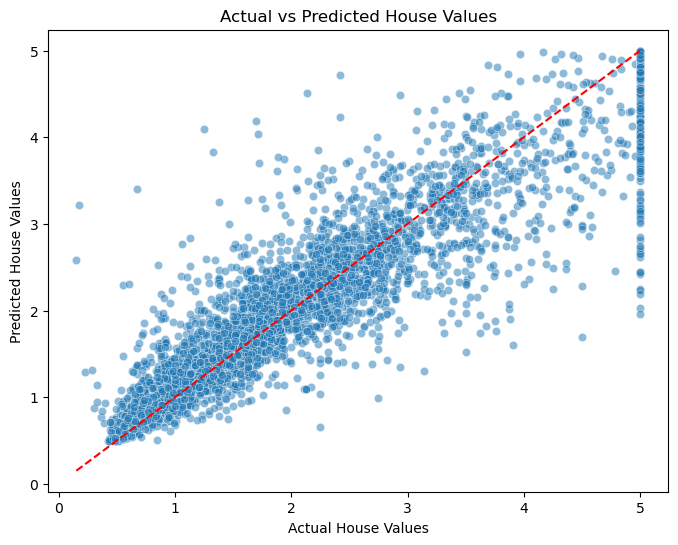

In [52]:
# Actual vs Predicted
plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.5)

plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],color='red',linestyle='--')

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')
plt.title('Actual vs Predicted House Values')
plt.show()

In [53]:
# Feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_regressor.feature_importances_
})

feature_importance = feature_importance.sort_values(by='Importance',ascending=False)

feature_importance

,Feature,Importance
0,MedInc,0.524871
5,AveOccup,0.138443
6,Latitude,0.088936
7,Longitude,0.088629
1,HouseAge,0.054593
2,AveRooms,0.044272
4,Population,0.030650
3,AveBedrms,0.029606


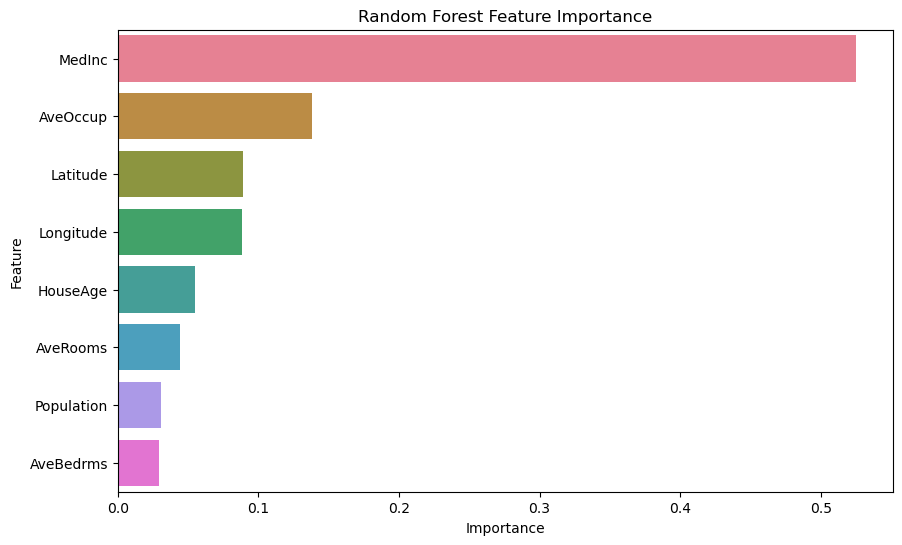

In [57]:
plt.figure(figsize=(10, 6))

sns.barplot(data=feature_importance,x='Importance',y='Feature',hue='Feature',palette='husl',legend=False)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

#### California Housing  Random Forest Regression

The Random Forest Regressor was developed to predict median house values using the California Housing dataset.

The model achieved the following test performance:

- **MAE:** 0.3275
- **MSE:** 0.2554
- **RMSE:** 0.5053
- **R² Score:** 0.8051

The results indicate that the model explains approximately 80.51% of the variation in median house values. The actual-versus-predicted visualization provides an additional assessment of prediction performance.

Feature importance analysis also helped identify the variables that contributed most to the model's predictions.

##### Limitations and Further Improvements

- The model was trained using default hyperparameters.
- Hyperparameter tuning could improve predictive performance.
- Cross-validation could provide a more reliable estimate of generalization.
- Feature importance measures should be interpreted carefully because correlated features can share or distort importance.

Overall, Random Forest Regression demonstrated good predictive performance on the California Housing dataset and provided a useful baseline for further experimentation.

## Classification

### Iris Dataset

In [59]:
# load dataset
from sklearn.datasets import load_iris
iris = load_iris()
iris_df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
iris_df['target'] = iris.target

print(iris_df.shape)
iris_df.head()

(150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [61]:
# features and targets
X = iris_df.iloc[:, :-1].values
y = iris_df.iloc[:, -1].values

In [62]:
# split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [66]:
# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [67]:
# Modelling
classifier = RandomForestClassifier(n_estimators=100, random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

Accuracy: 100.00%


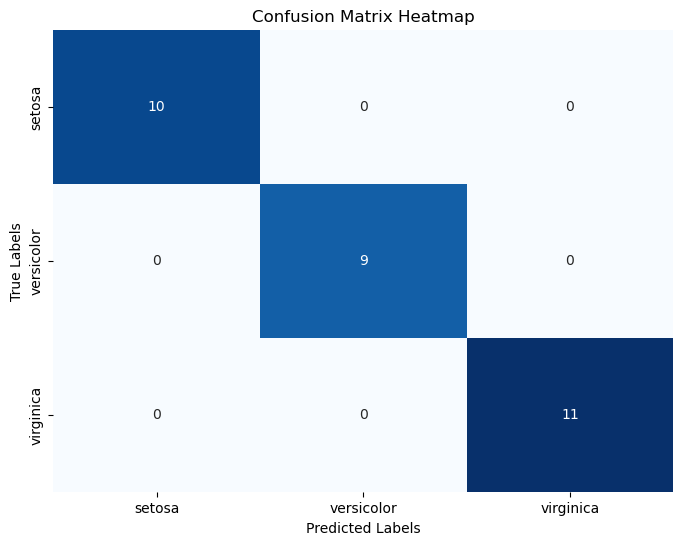

In [68]:
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False, xticklabels=iris.target_names, yticklabels=iris.target_names)

plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

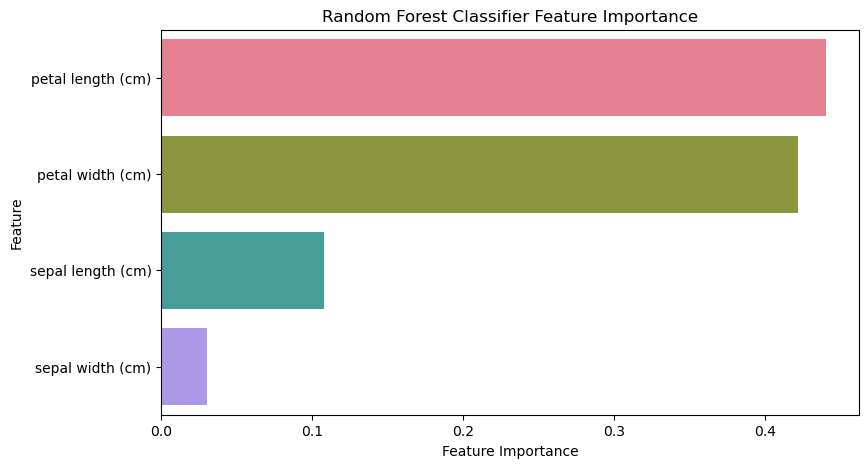

In [73]:
# feature importance
feature_importances = classifier.feature_importances_
feature_importance = pd.DataFrame({
    'Feature': iris.feature_names,
    'Importance': classifier.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(data=feature_importance,x='Importance',y='Feature',hue='Feature',palette='husl',legend=False)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Random Forest Classifier Feature Importance')
plt.show()

#### Petal width (cm) is the most important feature followed closely by petal length (cm). The sepal width (cm) and sepal length (cm) have lower importance in determining the model’s predictions. This indicates that the classifier relies more on the petal measurements to make predictions about the flower species.

### Breast Cancer Winconsin Dataset

In [76]:
# load dataset
cancer = load_breast_cancer()

cancer_df = pd.DataFrame(cancer.data,columns=cancer.feature_names)

cancer_df['target'] = cancer.target

print(cancer_df.shape)
cancer_df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [75]:
cancer_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [77]:
cancer_df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [78]:
# missing values
cancer_df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [79]:
# target variable analysis
cancer_df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

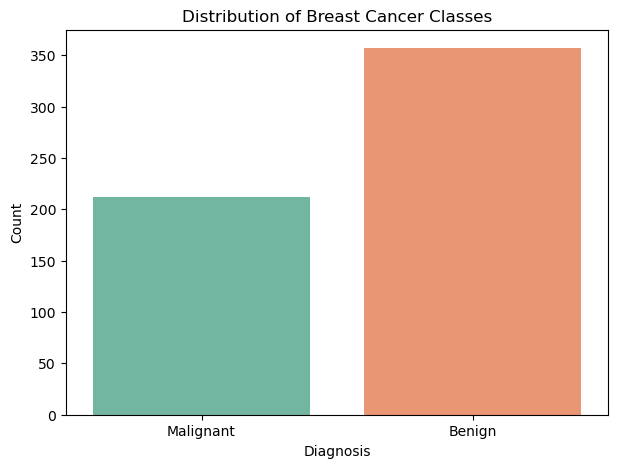

In [80]:
plt.figure(figsize=(7, 5))

sns.countplot(data=cancer_df,x='target',hue='target',palette='Set2',legend=False)

plt.xticks([0, 1], ['Malignant', 'Benign'])
plt.title('Distribution of Breast Cancer Classes')
plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.show()

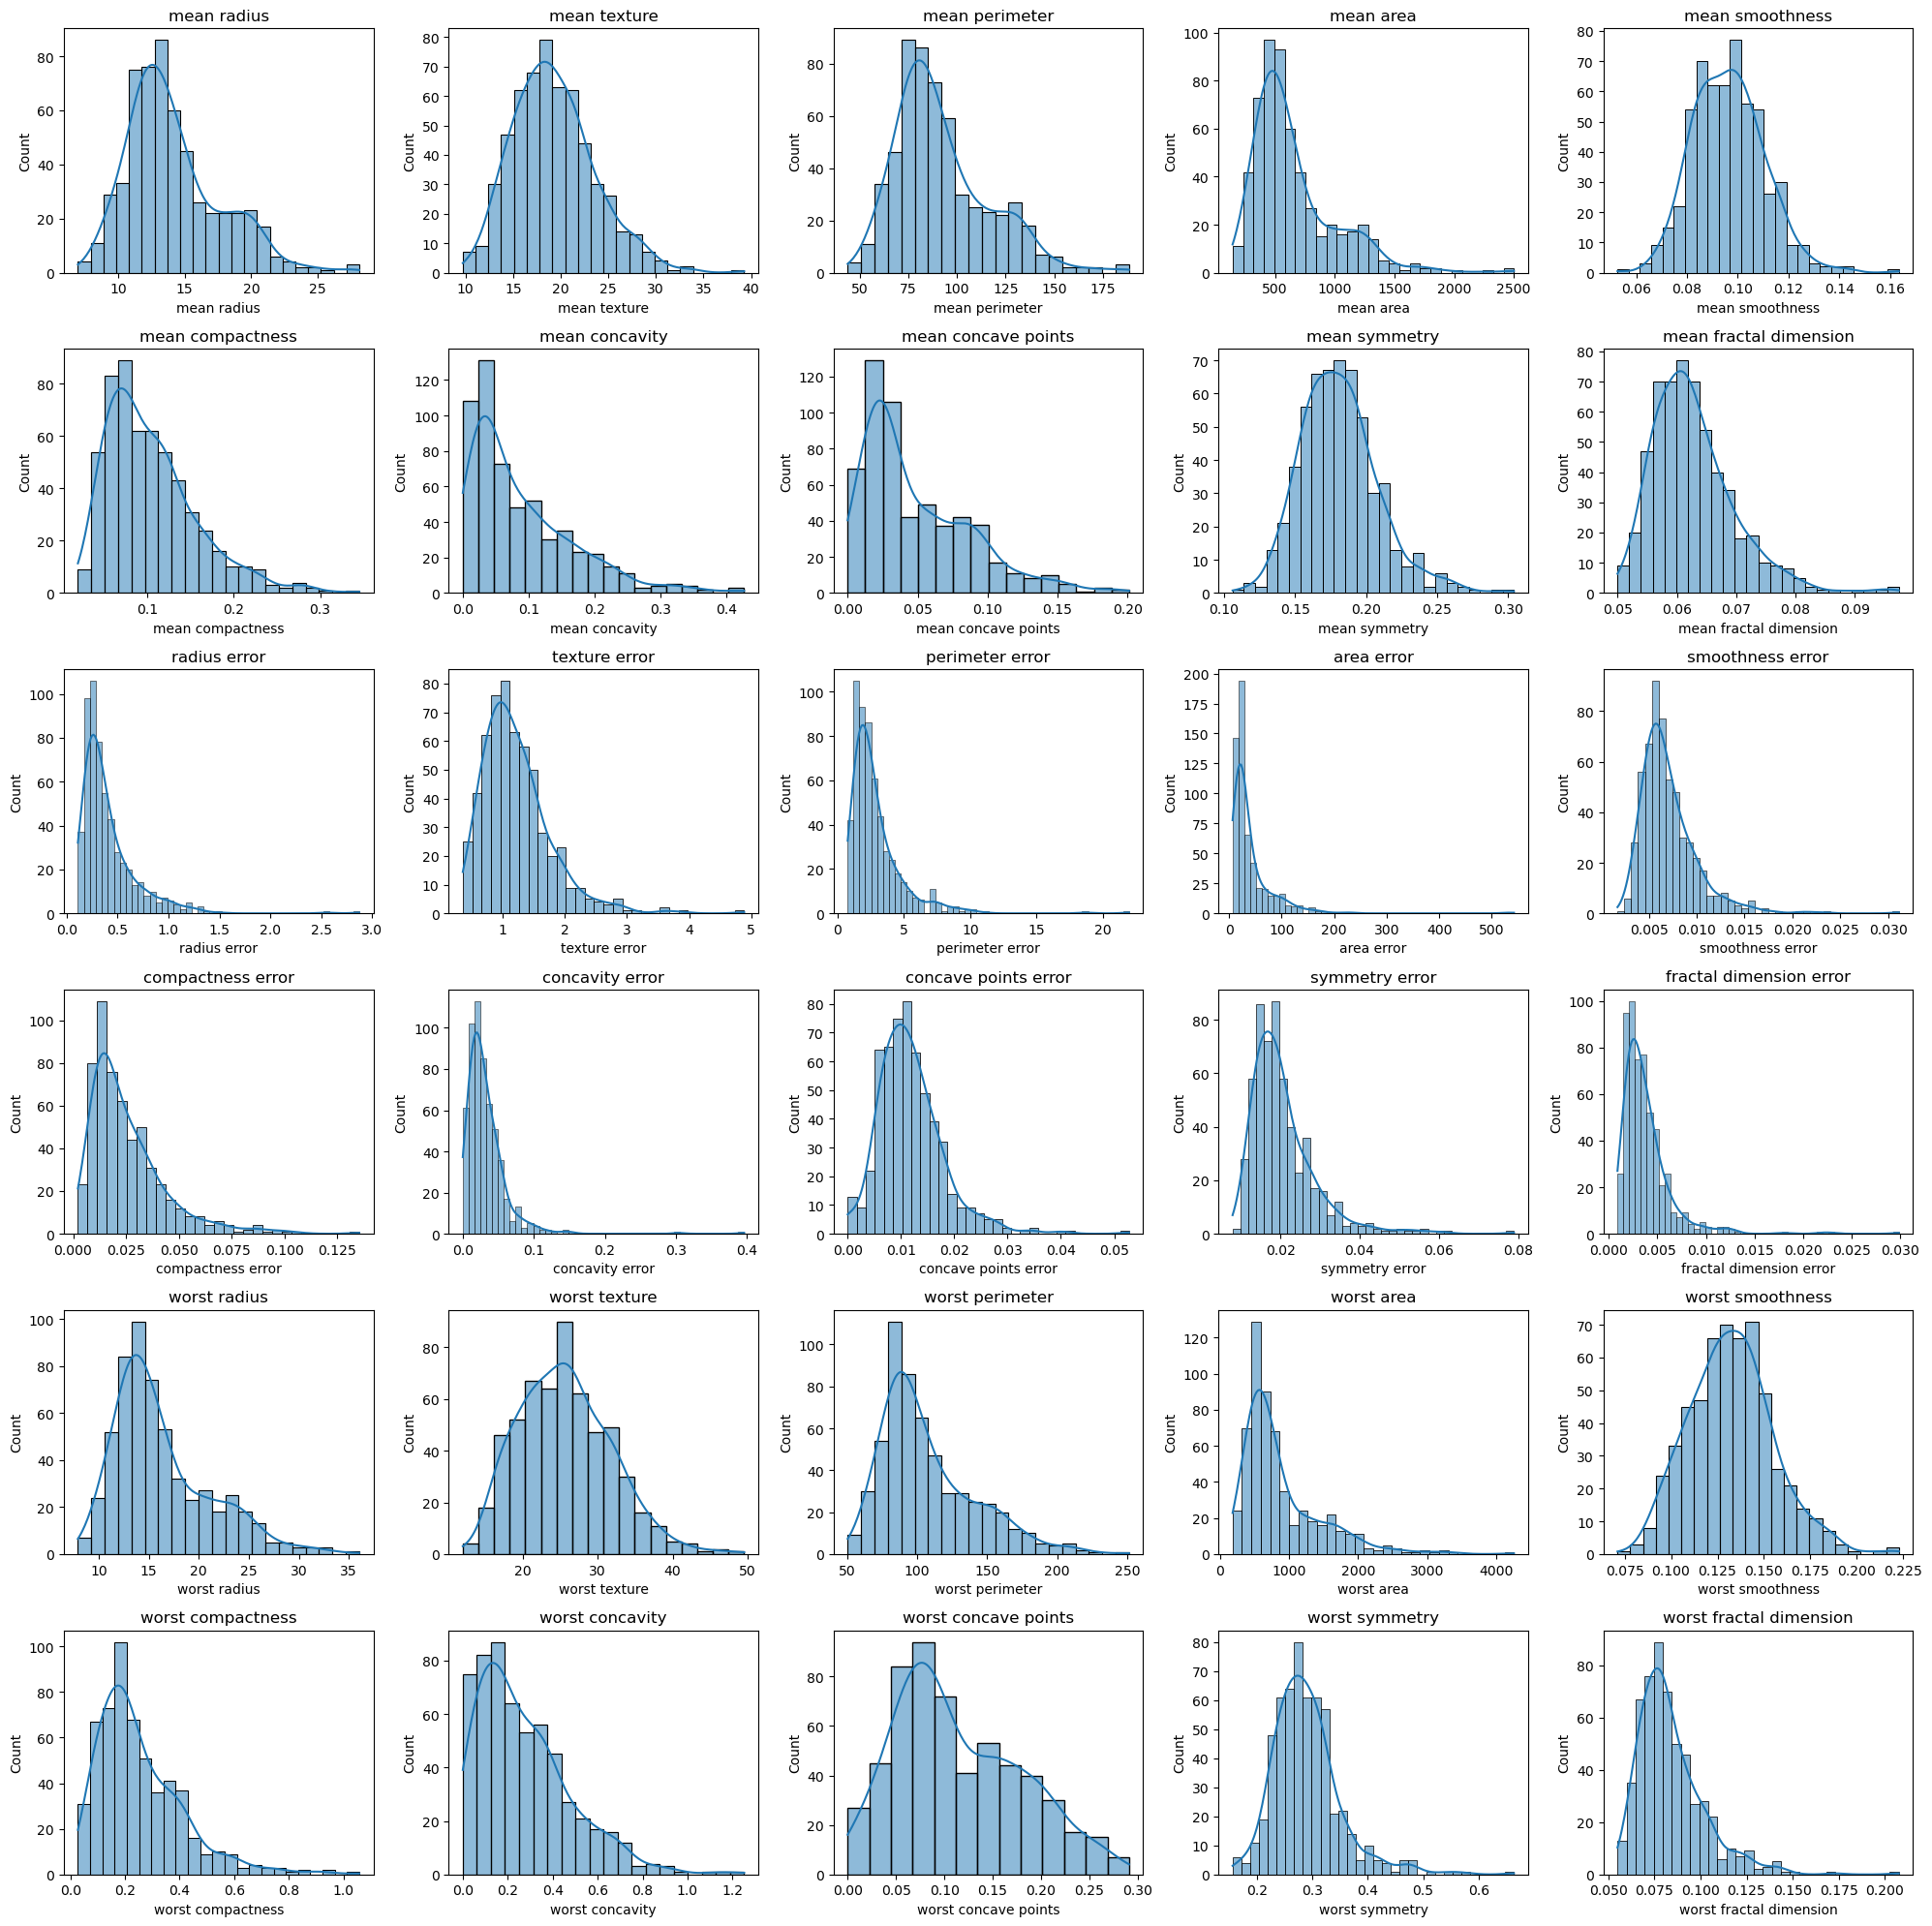

In [81]:
# feature distributions
features = cancer_df.drop(columns='target').columns

n_cols = 5
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 20))
axes = axes.flatten()

for i, column in enumerate(features):
    sns.histplot(data=cancer_df, x=column, kde=True, ax=axes[i])
    axes[i].set_title(column)

for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

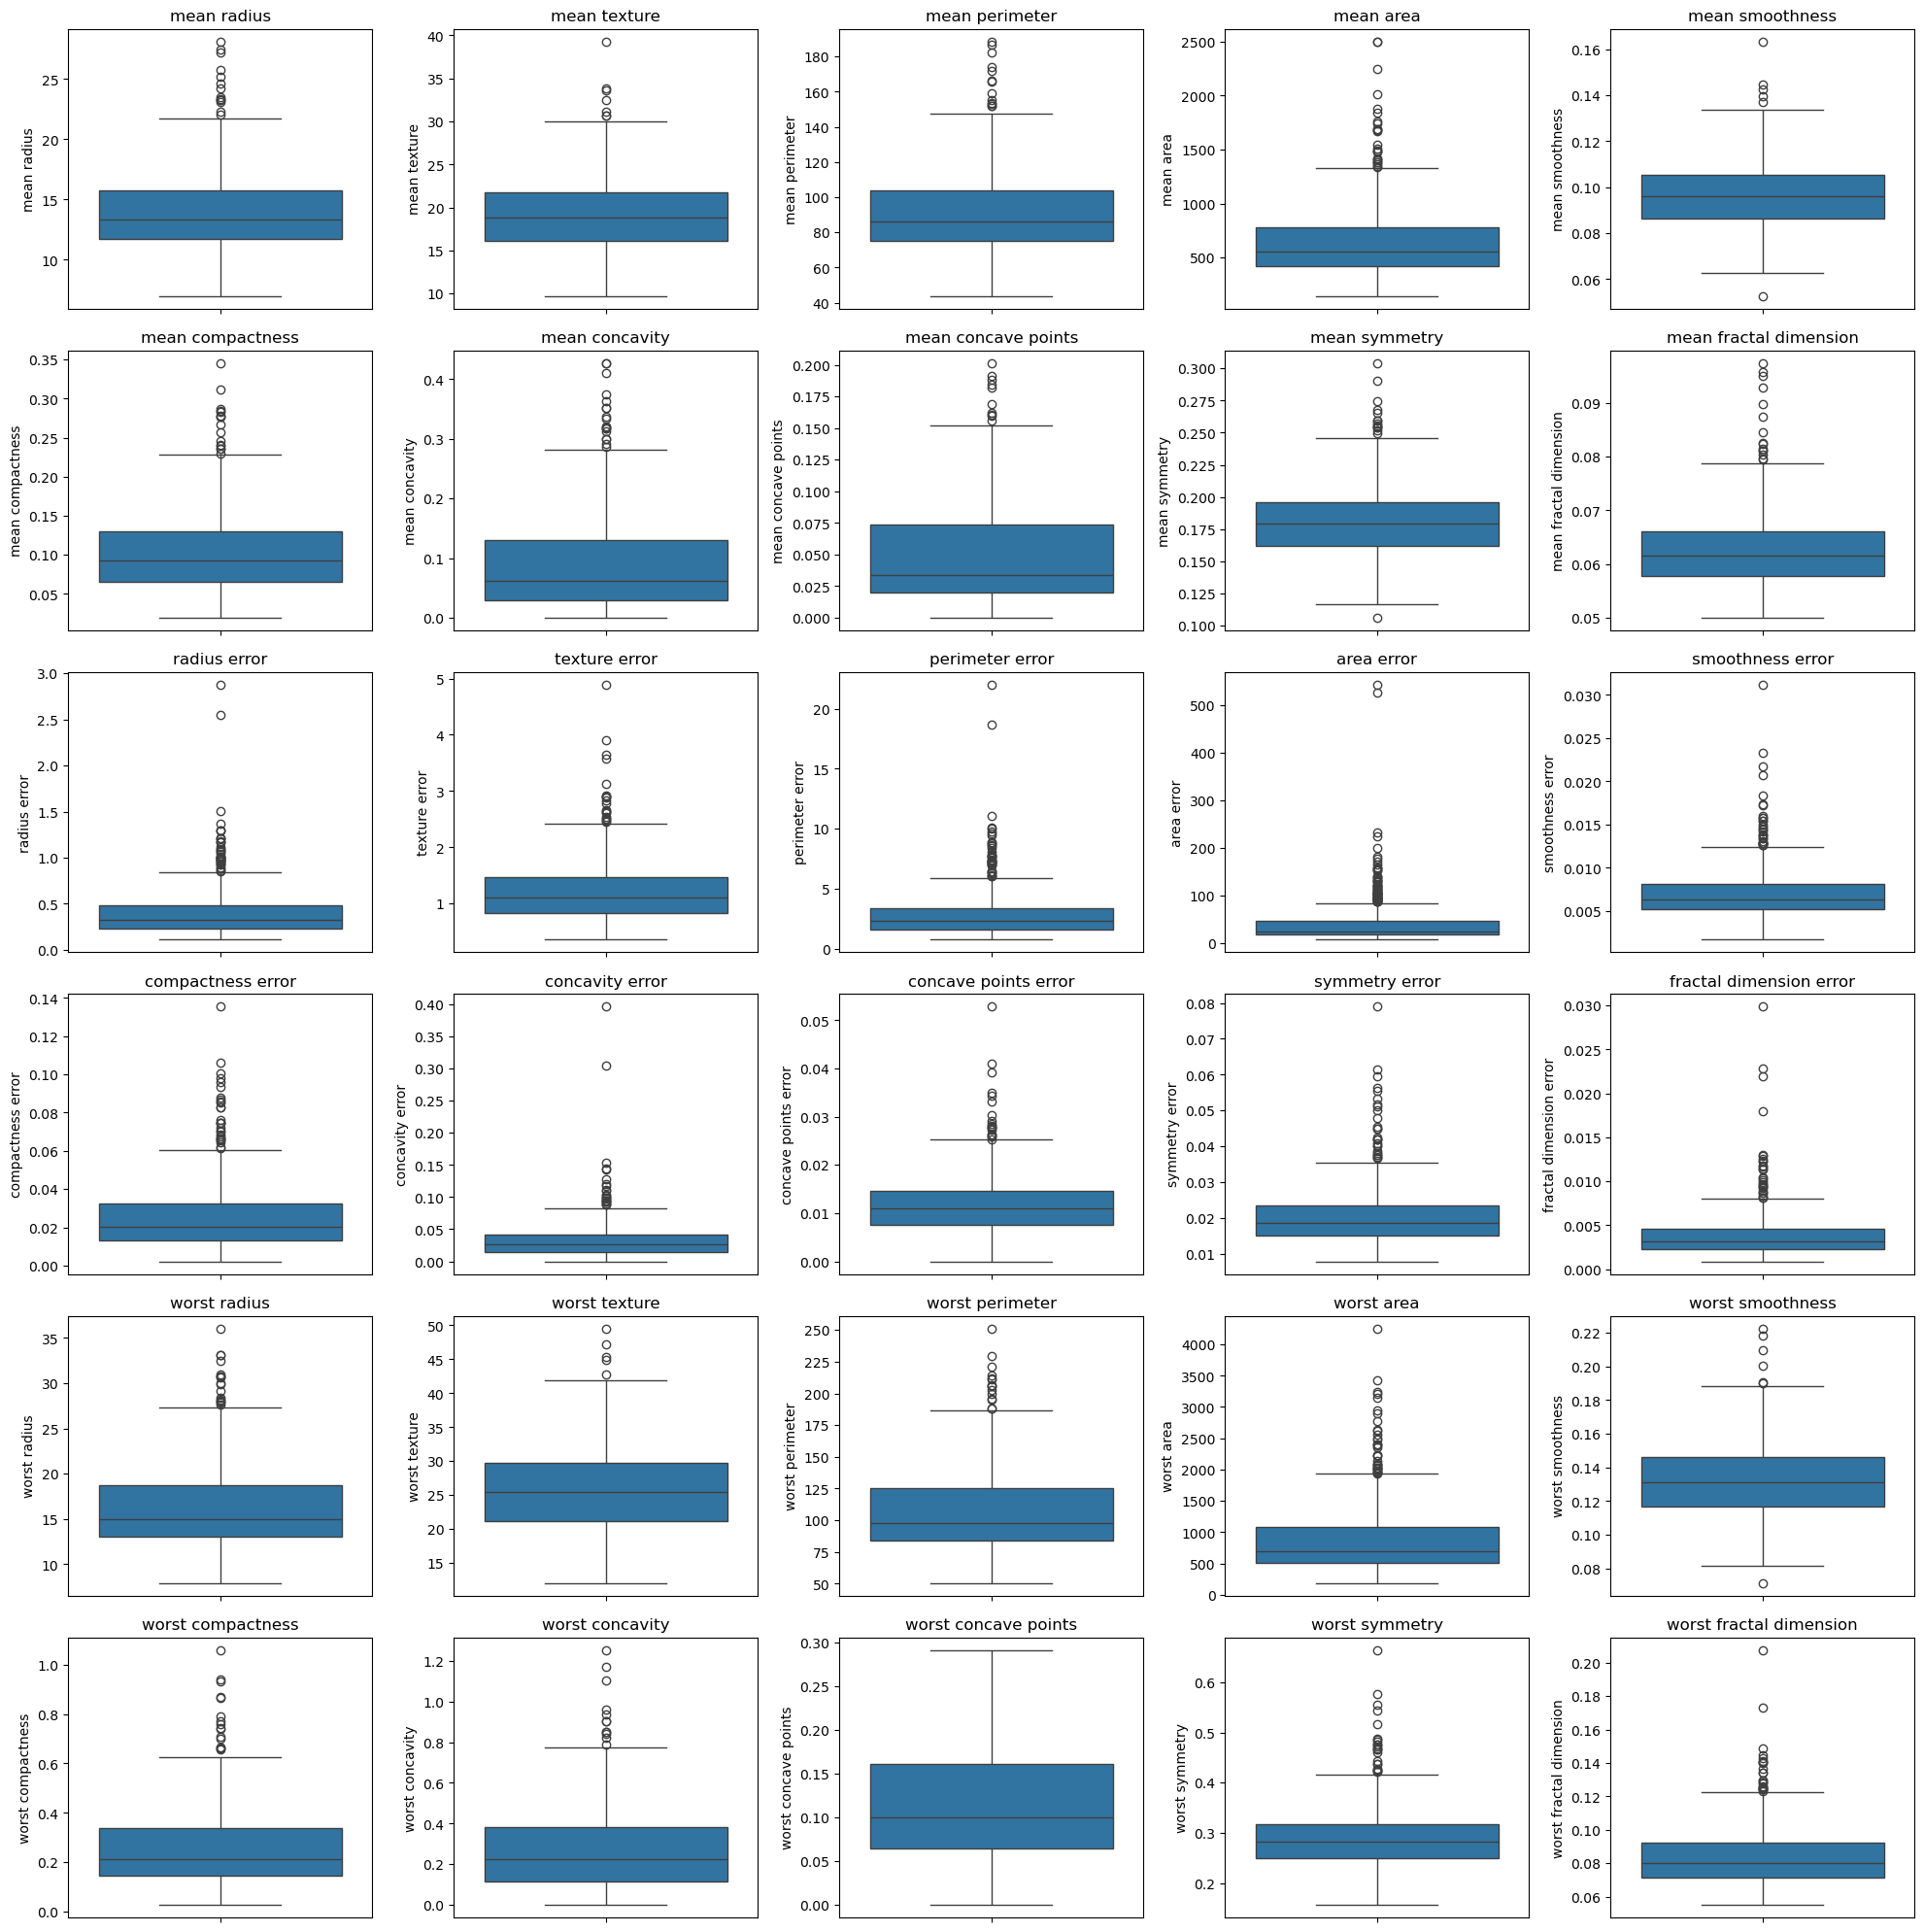

In [82]:
# Outlier analysis
n_cols = 5
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 20))
axes = axes.flatten()

for i, column in enumerate(features):
    sns.boxplot(data=cancer_df, y=column, ax=axes[i])
    axes[i].set_title(column)

for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

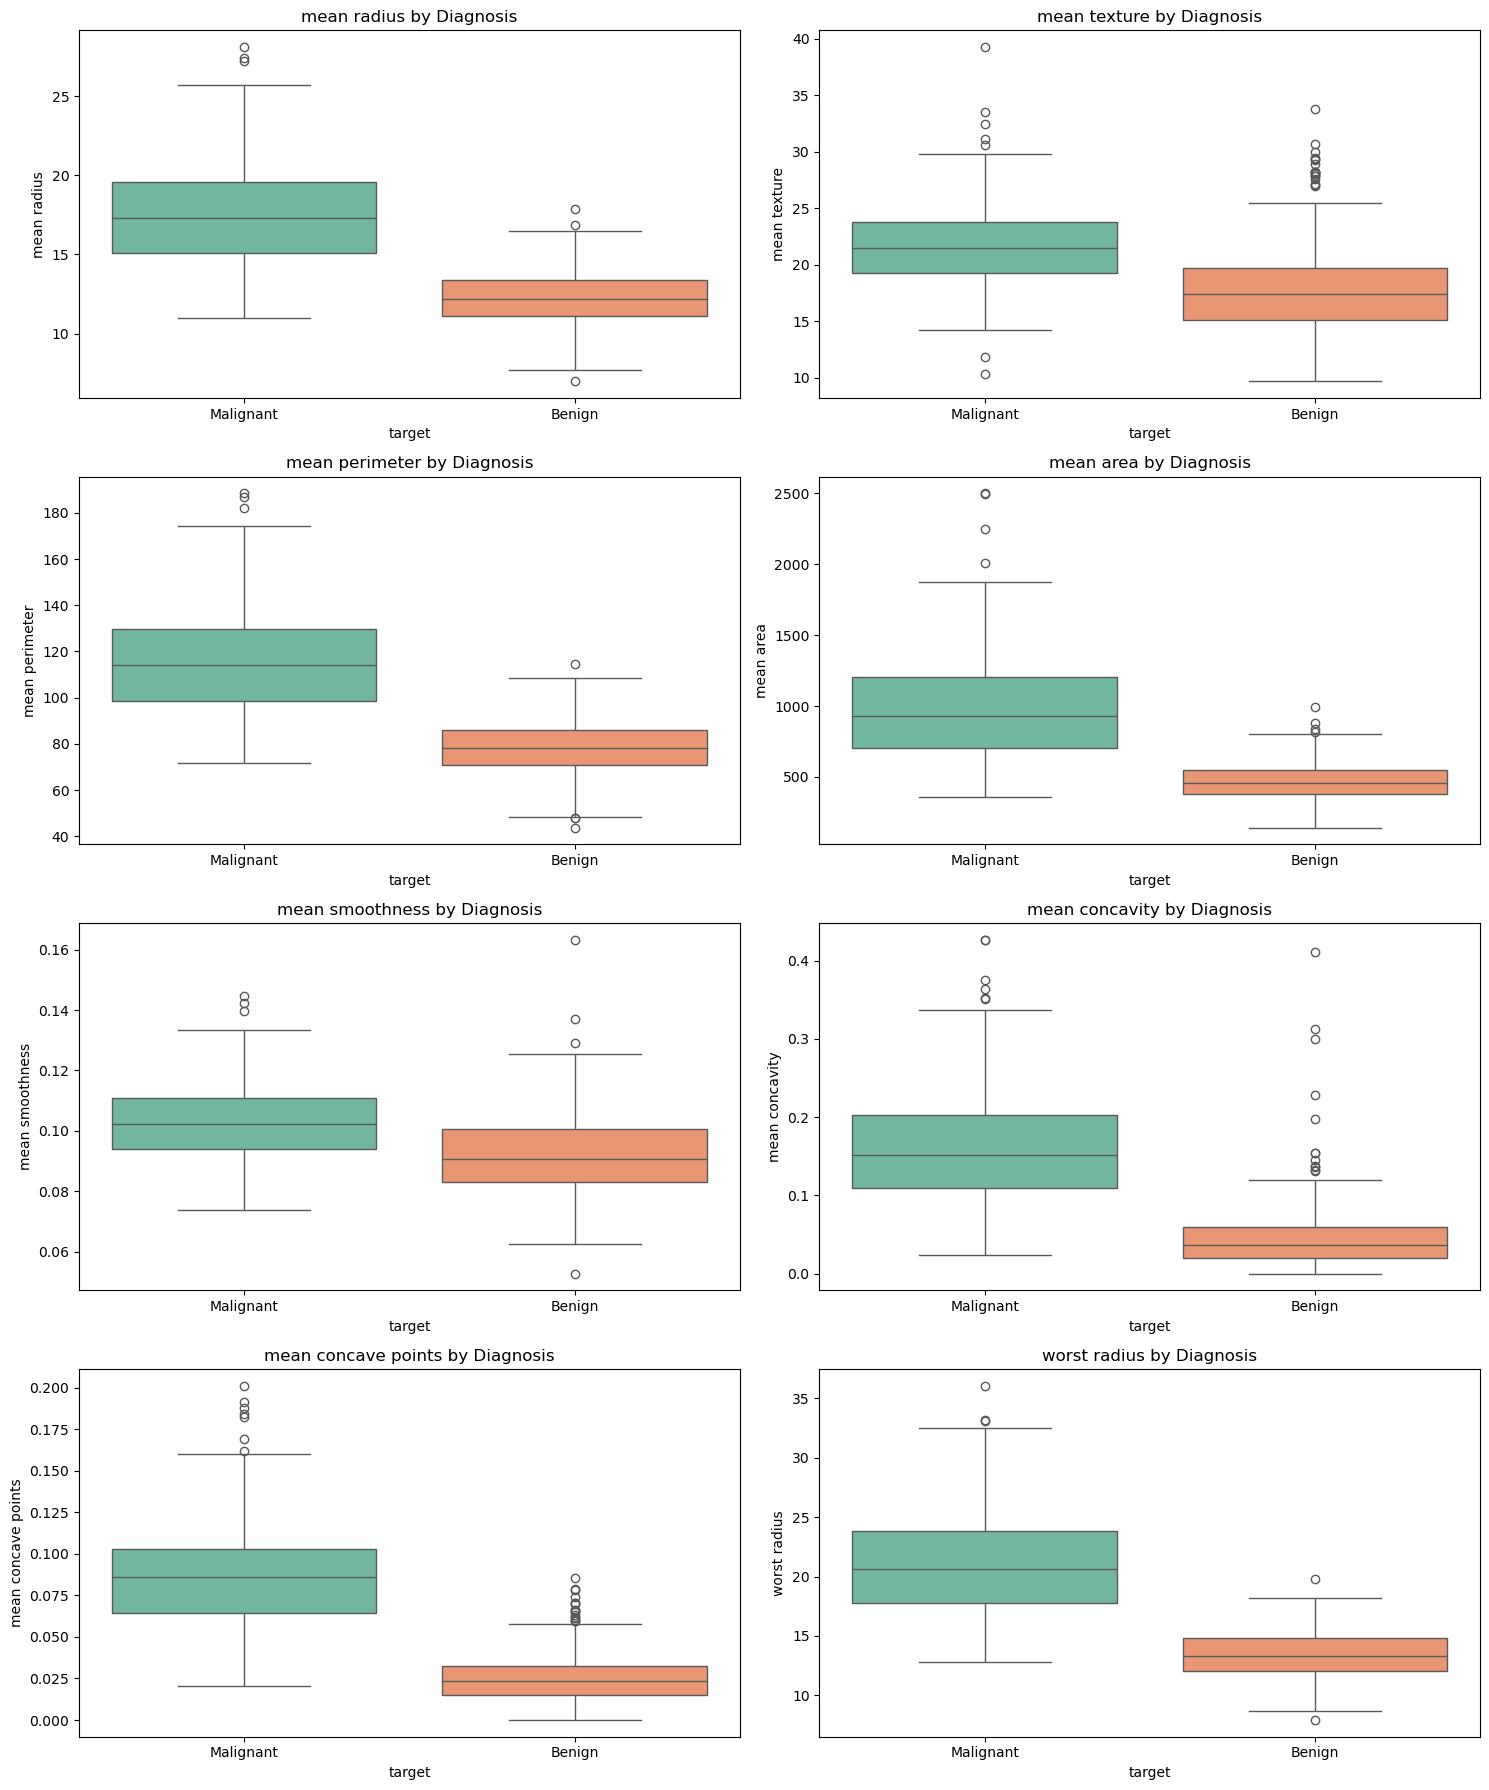

In [83]:
# feature rlships with target
selected_features = [
    'mean radius',
    'mean texture',
    'mean perimeter',
    'mean area',
    'mean smoothness',
    'mean concavity',
    'mean concave points',
    'worst radius'
]

fig, axes = plt.subplots(4, 2, figsize=(15, 18))
axes = axes.flatten()

for i, column in enumerate(selected_features):
    sns.boxplot(data=cancer_df,x='target',y=column,hue='target',palette='Set2',legend=False,ax=axes[i])

    axes[i].set_xticks([0, 1], ['Malignant', 'Benign'])
    axes[i].set_title(f'{column} by Diagnosis')

plt.tight_layout()
plt.show()

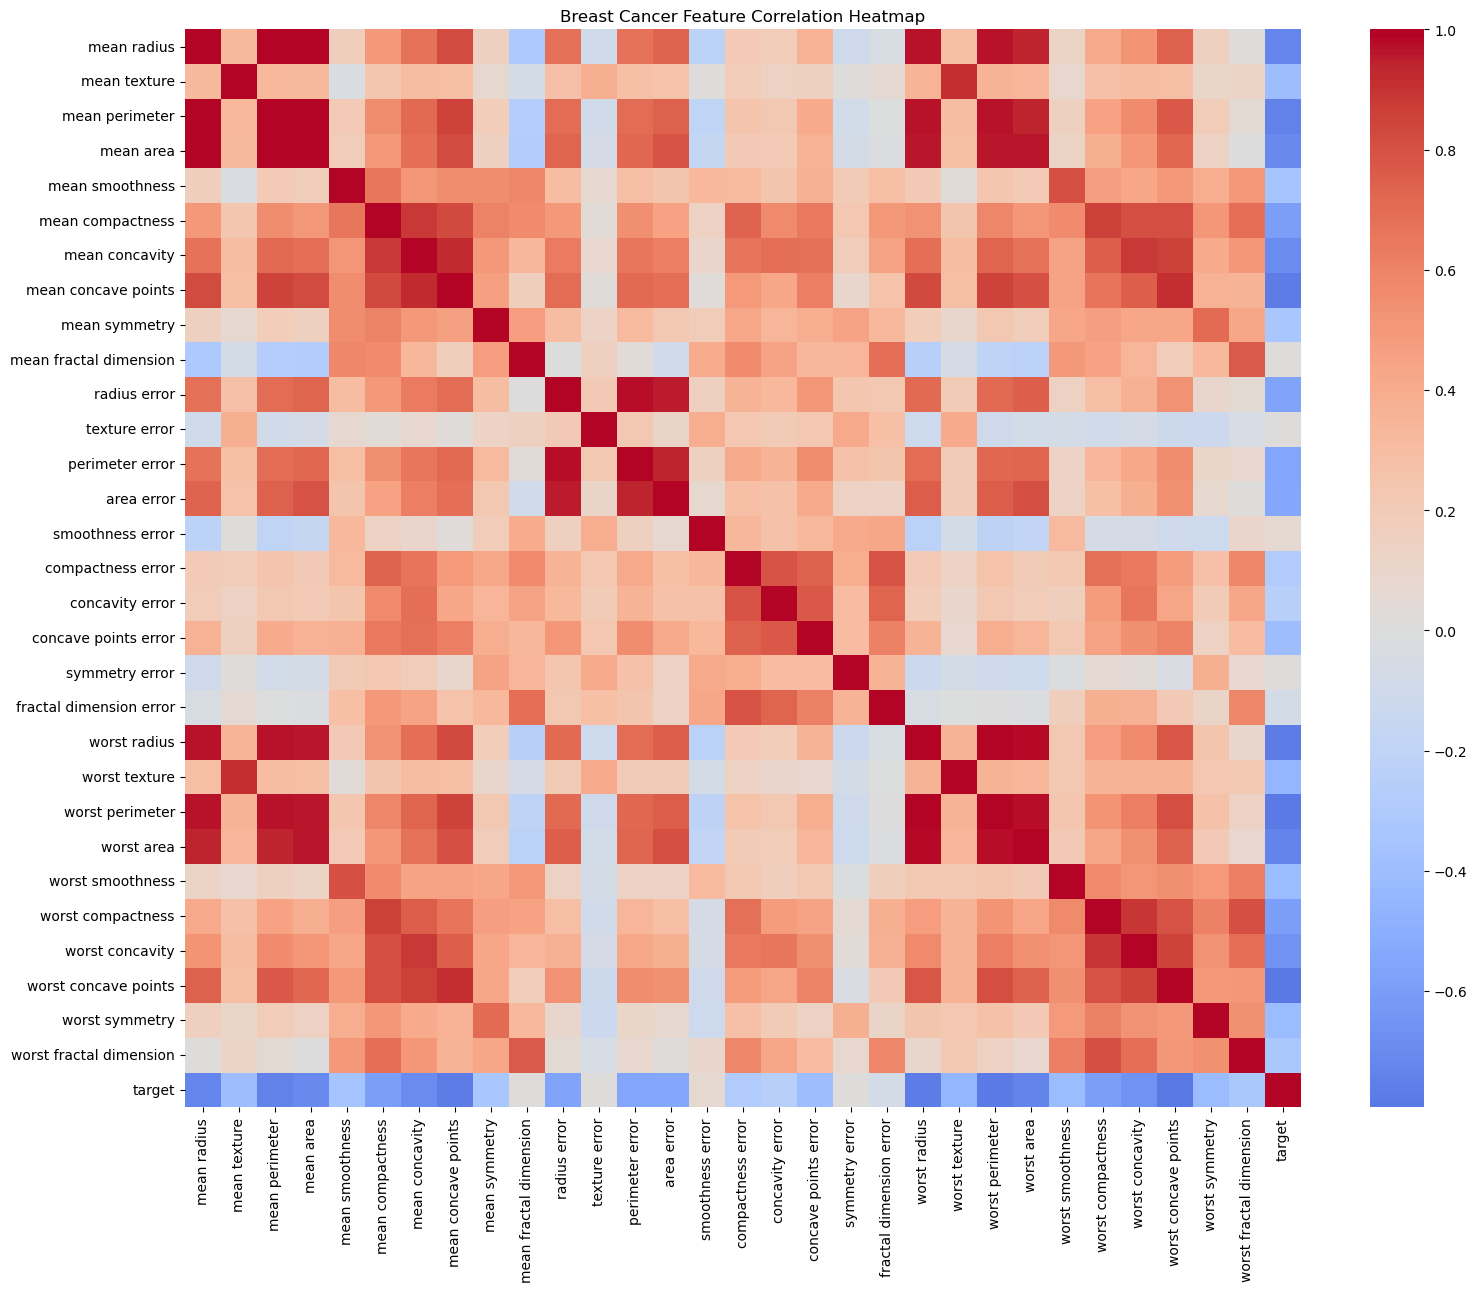

In [84]:
# Correlation analysis
plt.figure(figsize=(18, 14))

sns.heatmap(cancer_df.corr(),cmap='coolwarm',center=0)

plt.title('Breast Cancer Feature Correlation Heatmap')
plt.show()

In [86]:
# preprocessing
# separate features and targets
X = cancer_df.drop(columns='target')
y = cancer_df['target']
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (569, 30)
Target shape: (569,)


In [87]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (455, 30)
X_test: (114, 30)
y_train: (455,)
y_test: (114,)


In [88]:
print("Training set distribution:")
print(y_train.value_counts())

print("\nTesting set distribution:")
print(y_test.value_counts())

Training set distribution:
target
1    285
0    170
Name: count, dtype: int64

Testing set distribution:
target
1    72
0    42
Name: count, dtype: int64


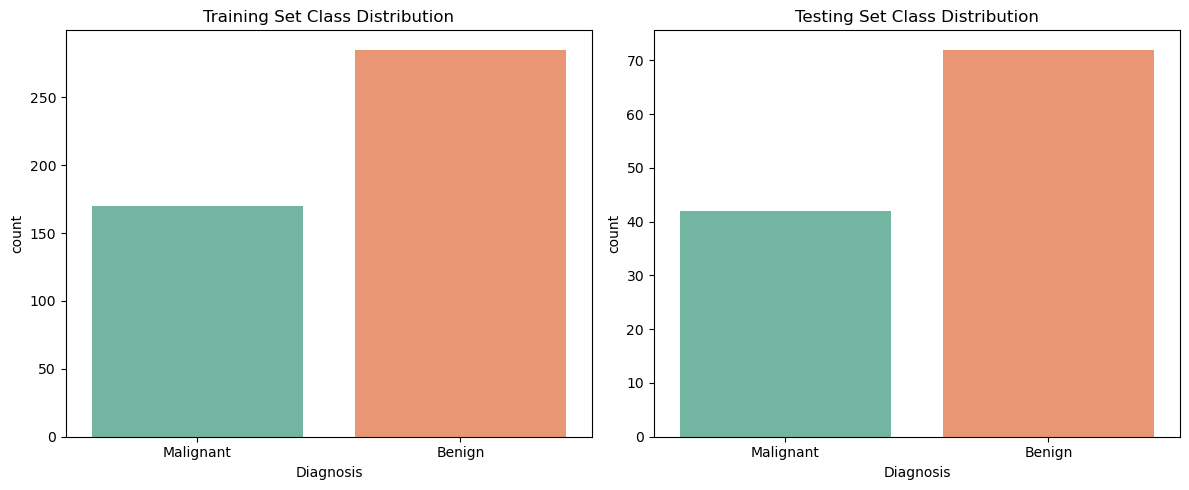

In [89]:
# class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=y_train, hue=y_train, palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Training Set Class Distribution')
axes[0].set_xticks([0, 1], ['Malignant', 'Benign'])
axes[0].set_xlabel('Diagnosis')

sns.countplot(x=y_test, hue=y_test, palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Testing Set Class Distribution')
axes[1].set_xticks([0, 1], ['Malignant', 'Benign'])
axes[1].set_xlabel('Diagnosis')

plt.tight_layout()
plt.show()

In [90]:
# Modelling
classifier = RandomForestClassifier(n_estimators=100,criterion='gini',random_state=42,n_jobs=-1)

classifier.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [91]:
# predictions
y_train_pred = classifier.predict(X_train)
y_test_pred = classifier.predict(X_test)

y_test_proba = classifier.predict_proba(X_test)[:, 1]

In [92]:
# Evaluation
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
roc_auc = roc_auc_score(y_test, y_test_proba)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Accuracy:  0.9561
Precision: 0.9589
Recall:    0.9722
F1 Score:  0.9655
ROC-AUC:   0.9937


In [93]:
print(classification_report(y_test,y_test_pred,target_names=cancer.target_names))

              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



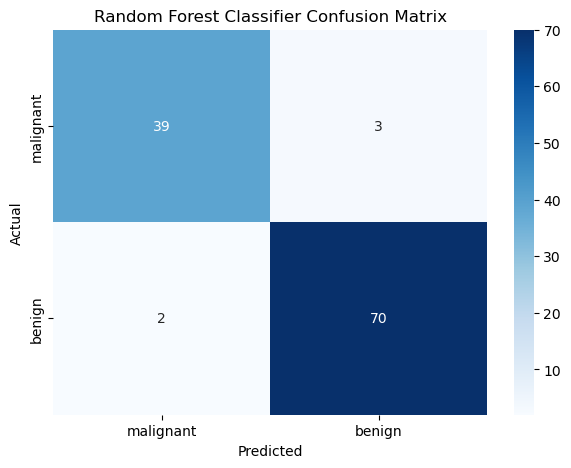

In [94]:
# confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=cancer.target_names,yticklabels=cancer.target_names)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Classifier Confusion Matrix')
plt.show()

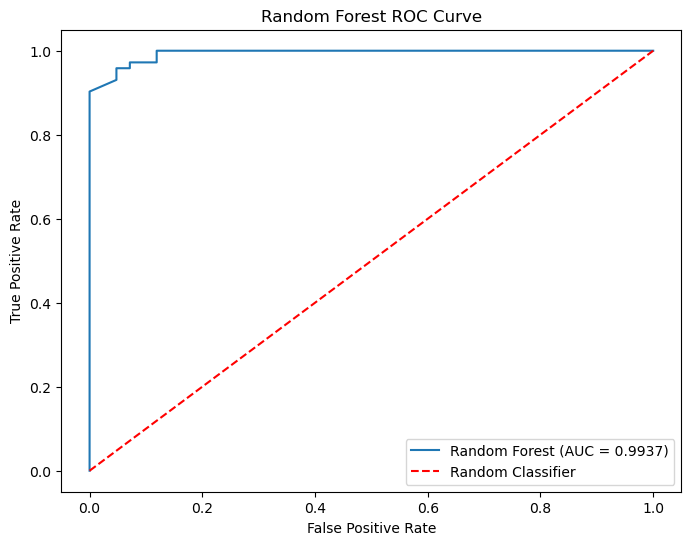

In [95]:
# ROC-AUC 
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest ROC Curve')
plt.legend()
plt.show()

In [96]:
# feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': classifier.feature_importances_
}).sort_values(by='Importance', ascending=False)

feature_importance

,Feature,Importance
23,worst area,0.140016
27,worst concave points,0.129530
20,worst radius,0.097696
7,mean concave points,0.090885
22,worst perimeter,0.072226
2,mean perimeter,0.069574
0,mean radius,0.068676
6,mean concavity,0.057638
3,mean area,0.049172
26,worst concavity,0.034340


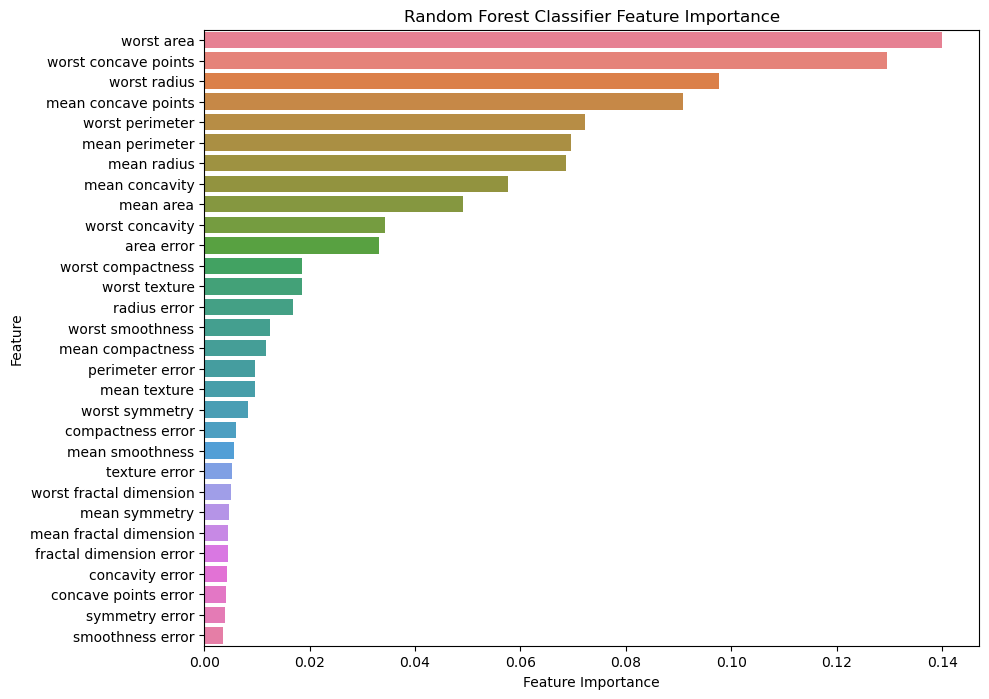

In [97]:
plt.figure(figsize=(10, 8))

sns.barplot(data=feature_importance,x='Importance',y='Feature',hue='Feature',palette='husl',legend=False)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Random Forest Classifier Feature Importance')
plt.show()

In [98]:
# Actual vs Predicted
comparison_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_test_pred
})

comparison_df['Actual'] = comparison_df['Actual'].map({
    0: 'Malignant',
    1: 'Benign'
})

comparison_df['Predicted'] = comparison_df['Predicted'].map({
    0: 'Malignant',
    1: 'Benign'
})

comparison_df.head(15)

,Actual,Predicted
256,Malignant,Malignant
428,Benign,Benign
501,Malignant,Malignant
363,Benign,Malignant
564,Malignant,Malignant
464,Benign,Benign
358,Benign,Benign
343,Malignant,Malignant
516,Malignant,Malignant
567,Malignant,Malignant


In [99]:
# model comparison
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Testing Accuracy:  {test_accuracy:.4f}")

Training Accuracy: 1.0000
Testing Accuracy:  0.9561


#### Breast cancer 

The Random Forest Classifier was implemented using the Breast Cancer Wisconsin dataset to predict whether a tumour is malignant or benign.

The model achieved the following test performance:

- **Accuracy:** 95.61%
- **Precision:** 95.89%
- **Recall:** 97.22%
- **F1 Score:** 96.55%
- **ROC-AUC:** 99.37%

The results demonstrate strong classification performance, with the model correctly classifying approximately 95.61% of the test observations.

The classification report showed strong performance across both malignant and benign classes. However, the model still misclassified some observations, particularly malignant cases predicted as benign. This is an important consideration in medical classification.

Feature importance analysis provided insight into which tumour measurements contributed most to the model's predictions.

### Limitations and Further Improvements

- The model was trained using initial hyperparameter settings.
- Hyperparameter tuning could improve its performance.
- Cross-validation could provide a more reliable estimate of generalization.
- Feature importance does not necessarily imply causation.
- The dataset is relatively small and results should not be interpreted as evidence of clinical readiness.

Overall, Random Forest demonstrated strong performance on this classification task and provided a useful example of ensemble learning applied to a medical dataset.